In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import matplotlib.path as mpath
import cartopy.feature as cfeature
from regional_mom6 import regridding as rgd
from pathlib import Path
from matplotlib.animation import FuncAnimation
from pyproj import CRS, Transformer,Geod



In [9]:
arctic_grid = 3413
antarctic_grid = 3031
for grid_num in [arctic_grid, antarctic_grid]:
    crs = CRS.from_epsg(grid_num)   # NSIDC standard for Arctic
    transformer = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
    geod = Geod(ellps="WGS84")


    x_min, x_max = -3500000, 3500000
    y_min, y_max = -3500000, 3500000
    nx, ny = 301, 301

    new_x = np.linspace(x_min, x_max, nx)
    new_y = np.linspace(y_min, y_max, ny)
    xx, yy = np.meshgrid(new_x, new_y)

    # Transform to lat/lon
    lon, lat = transformer.transform(xx, yy)
    dx = np.full((ny, nx-1), np.nan)

    # Distance between (i, j) and (i, j+1)
    az12, az21, dist = geod.inv(
        lon[:, :-1], lat[:, :-1],
        lon[:, 1:],  lat[:, 1:]
    )

    dx[:, :] = dist  # in meters
    dy = np.full((ny-1, nx), np.nan)

    # Distance between (i, j) and (i+1, j)
    az12, az21, dist = geod.inv(
        lon[:-1, :], lat[:-1, :],
        lon[1:, :],  lat[1:, :]
    )

    dy[:, :] = dist
    area = np.full((ny - 1, nx - 1), np.nan)

    for j in range(ny - 1):
        for i in range(nx - 1):
            # 4 corners of the cell
            lons = [lon[j, i], lon[j, i+1], lon[j+1, i+1], lon[j+1, i]]
            lats = [lat[j, i], lat[j, i+1], lat[j+1, i+1], lat[j+1, i]]

            area_cell,_ = geod.polygon_area_perimeter(lons, lats)
            area[j, i] = abs(area_cell)  # in m²
    angle_dx = np.full((ny, nx), np.nan)

    az12, _, _ = geod.inv(
        lon[:, :-1], lat[:, :-1],
        lon[:, 1:],  lat[:, 1:]
    )

    # angle from east in radians
    angle_dx[:, :-1] = np.deg2rad(az12)
    hgrid  = xr.Dataset()
    hgrid = xr.Dataset({
        "x": (["nyp", "nxp"], lon, {"units": "degrees"}),
        "y": (["nyp", "nxp"], lat, {"units": "degrees"}),
        "dx": (["nyp", "nx"], dx, {"units": "meters"}),
        "dy": (["ny", "nxp"], dy, {"units": "meters"}),
        "area": (["ny", "nx"], area, {"units": "m2"}),
        "angle_dx": (["nyp", "nxp"], angle_dx, {"units": "radians"}),
    })
    hgrid.to_netcdf(f"replica_grid_{grid_num}.nc")

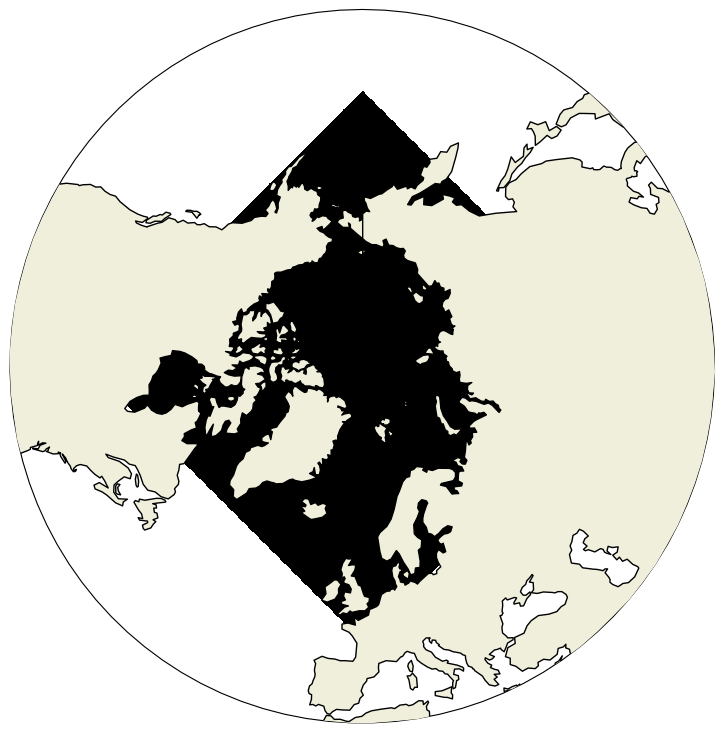

In [10]:
# make circular boundary for polar stereographic circular plots
hgrid = xr.open_dataset("replica_grid_3413.nc")
theta = np.linspace(0, 2*np.pi, 100)
center, radius = [0.5, 0.5], 0.5
verts = np.vstack([np.sin(theta), np.cos(theta)]).T
circle = mpath.Path(verts * radius + center)

# define the colormap
cmap = plt.cm.get_cmap('rainbow')  

# set up the figure with a North Polar Stereographic projection
fig = plt.figure(figsize=(20,20))
ax = fig.add_subplot(1,2,1, projection=ccrs.NorthPolarStereo())
ax.set_boundary(circle, transform=ax.transAxes)
ax.add_feature(cfeature.LAND,zorder=100,edgecolor='k')

# sets the latitude / longitude boundaries of the plot
ax.set_extent([0, 360, 35, 90], crs=ccrs.PlateCarree()) # [west_lon, east_lon, south_lat, north_lat]
mesh = ax.pcolormesh(hgrid.x,
                     hgrid.y,
                       np.zeros_like(hgrid.x),
                     cmap="grey",
                     transform=ccrs.PlateCarree())




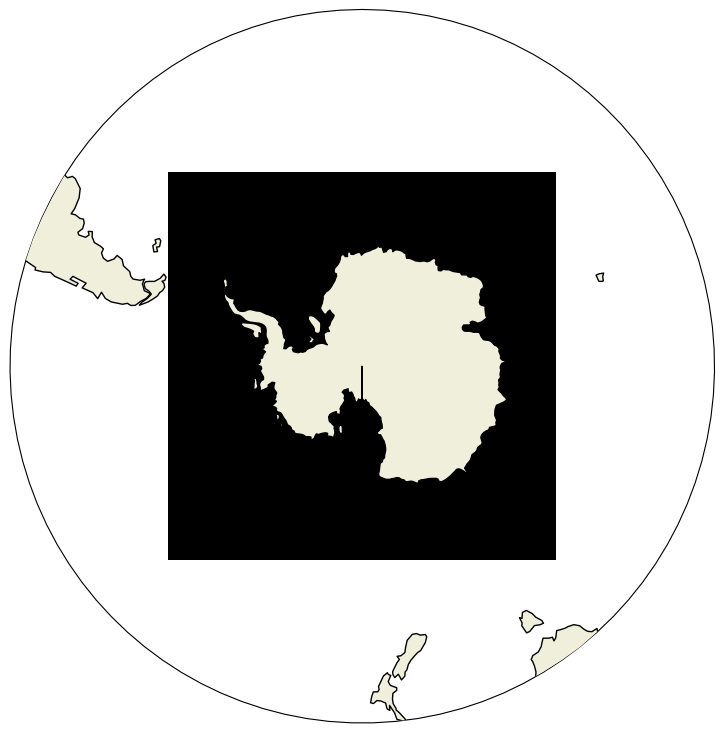

In [11]:
# make circular boundary for polar stereographic circular plots
antarctic_hgrid = xr.open_dataset("replica_grid_3031.nc")
theta = np.linspace(0, 2*np.pi, 100)
center, radius = [0.5, 0.5], 0.5
verts = np.vstack([np.sin(theta), np.cos(theta)]).T
circle = mpath.Path(verts * radius + center)

# define the colormap
cmap = plt.cm.get_cmap('rainbow')  

# set up the figure with a North Polar Stereographic projection
fig = plt.figure(figsize=(20,20))
ax = fig.add_subplot(1,2,1, projection=ccrs.SouthPolarStereo())
ax.set_boundary(circle, transform=ax.transAxes)
ax.add_feature(cfeature.LAND,zorder=100,edgecolor='k')

# sets the latitude / longitude boundaries of the plot
ax.set_extent([0, 360, -90, -35], crs=ccrs.PlateCarree()) # [west_lon, east_lon, south_lat, north_lat]
mesh = ax.pcolormesh(antarctic_hgrid.x,
                     antarctic_hgrid.y,
                       np.zeros_like(antarctic_hgrid.x),
                     cmap="grey",
                     transform=ccrs.PlateCarree())


